# GIAI ĐOẠN 05: THỰC NGHIỆM 1.3 - SO SÁNH MẠNG HỒI QUY THỜI GIAN (BI-GRU VS BI-LSTM)
### Bộ dữ liệu: VSL400 (400 Từ vựng, Góc nhìn đơn Front-View, 64 Timesteps, 450 Chiều Đặc trưng)
---
**Mục tiêu học thuật của Thực nghiệm 1.3**:
1. Kế thừa khối trích xuất không gian vượt trội từ Thực nghiệm 1.2 (**Multi-Scale Inception 1D-CNN** với các kernel $k=1, 3, 5$ song song và liên kết tàn dư Residual).
2. Khảo sát năng lực mô hình hóa chuỗi cử chỉ theo thời gian ($T=64$ khung hình) bằng mạng **Bi-directional LSTM (Bi-LSTM)** thay thế cho Bi-GRU.
3. Đặt lên bàn cân so sánh thực nghiệm đối đầu giữa Bi-GRU và Bi-LSTM: kiểm tra xem cơ chế ô nhớ trạng thái độc lập (Cell State $C_t$) cùng 3 cổng điều khiển (Input, Forget, Output Gate) của LSTM có mang lại lợi thế ghi nhớ ngữ cảnh cử chỉ dài hơn so với cơ chế tinh gọn của GRU hay không.
4. Hoàn thiện bảng đối soát 3 mô hình của Tuần 1 (Baseline vs Inception Bi-GRU vs Inception Bi-LSTM) để chính thức **Khóa kiến trúc Backbone cơ sở** trước khi bước sang Tuần 2 (Tích hợp Cơ chế Attention).


---
## 1. Thiết Lập Môi Trường & Siêu Tham Số Huấn Luyện (Setup & Hyperparameters)


In [19]:
import os
import sys
import json
import time
import random
from pathlib import Path

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import interp1d
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, accuracy_score

import tensorflow as tf
import keras
from keras import layers

# Đảm bảo tính tái lập kết quả thực nghiệm (Reproducibility)
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# Thiết lập đường dẫn thư mục dự án chuẩn hóa
def detect_project_root() -> Path:
    cur = Path.cwd()
    for p in [cur, cur.parent, cur.parent.parent]:
        if (p / "data" / "processed").exists():
            return p.resolve()
    return cur.resolve()

PROJECT_ROOT    = detect_project_root()
DATA_DIR        = PROJECT_ROOT / "data" / "processed"
SPLITS_DIR      = DATA_DIR / "splits"
CACHE_DIR       = DATA_DIR / "cache"
CHECKPOINTS_DIR = PROJECT_ROOT / "experiments" / "checkpoints"
LOGS_DIR        = PROJECT_ROOT / "experiments" / "logs"
RESULTS_DIR     = PROJECT_ROOT / "experiments" / "results"
REPORTS_DIR     = PROJECT_ROOT / "reports"
FIGURES_DIR     = REPORTS_DIR / "figures"

for d in [CACHE_DIR, CHECKPOINTS_DIR, LOGS_DIR, RESULTS_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Siêu tham số chuẩn hóa toàn cục
TARGET_FRAMES   = 64
BATCH_SIZE      = 64
NUM_CLASSES     = 400
FEATURE_DIM     = 450

print(f"Thư mục gốc dự án      : {PROJECT_ROOT}")
print(f"TensorFlow / Keras      : {tf.__version__} / {keras.__version__}")
print(f"Cấu hình huấn luyện     : T={TARGET_FRAMES} frames | Batch Size={BATCH_SIZE} | Số lớp={NUM_CLASSES}")
print(f"Chiều vector đặc trưng  : {FEATURE_DIM}D (225D Tọa độ không gian + 225D Đạo hàm vận tốc)")


Thư mục gốc dự án      : D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System
TensorFlow / Keras      : 2.16.1 / 3.12.4
Cấu hình huấn luyện     : T=64 frames | Batch Size=64 | Số lớp=400
Chiều vector đặc trưng  : 450D (225D Tọa độ không gian + 225D Đạo hàm vận tốc)


---
## 2. Nạp Phân Vùng Dữ Liệu Signer-Disjoint (Data Split Verification)

Giao thức phân chia đảm bảo tính khách quan tuyệt đối: Tập Huấn luyện (Train), Kiểm định (Validation) và Kiểm thử (Test) không có sự trùng lặp người ký (Signer-Disjoint Protocol).


In [20]:
# 1. Nạp từ điển ánh xạ từ vựng
with open(DATA_DIR / "gloss_to_id.json", "r", encoding="utf-8") as f:
    gloss_to_id = json.load(f)
with open(DATA_DIR / "id_to_gloss.json", "r", encoding="utf-8") as f:
    id_to_gloss = {int(k): v for k, v in json.load(f).items()}

# 2. Nạp phân vùng mới (Phương án A - Part-Stratified Disjoint)
train_df = pd.read_csv(SPLITS_DIR / "train_front.csv")
val_df   = pd.read_csv(SPLITS_DIR / "val_front.csv")
test_df  = pd.read_csv(SPLITS_DIR / "test_front.csv")

for df in [train_df, val_df, test_df]:
    df["label"] = df["label"].astype(int)

train_signers = sorted(train_df["signer_id"].astype(str).str.zfill(3).unique())
val_signers   = sorted(val_df["signer_id"].astype(str).str.zfill(3).unique())
test_signers  = sorted(test_df["signer_id"].astype(str).str.zfill(3).unique())

# Kiểm tra triệt để nguy cơ rò rỉ Signer
assert set(train_signers).isdisjoint(set(val_signers)), "Lỗi rò rỉ Train-Val!"
assert set(train_signers).isdisjoint(set(test_signers)), "Lỗi rò rỉ Train-Test!"
assert set(val_signers).isdisjoint(set(test_signers)), "Lỗi rò rỉ Val-Test!"

summary_split_df = pd.DataFrame([
    {"Phân vùng": "Huấn luyện (Train)", "Số mẫu": len(train_df), "Signers": len(train_signers), "Danh sách": f"{', '.join(train_signers[:5])} ... ({len(train_signers)} signers)", "Số Gloss": train_df["gloss"].nunique()},
    {"Phân vùng": "Kiểm định (Val)",   "Số mẫu": len(val_df),   "Signers": len(val_signers),   "Danh sách": ", ".join(val_signers), "Số Gloss": val_df["gloss"].nunique()},
    {"Phân vùng": "Kiểm thử (Test)",   "Số mẫu": len(test_df),  "Signers": len(test_signers),  "Danh sách": ", ".join(test_signers), "Số Gloss": test_df["gloss"].nunique()}
])
display(summary_split_df)

,Phân vùng,Số mẫu,Signers,Danh sách,Số Gloss
0,Huấn luyện (Train),17789,20,"001, 002, 003, 004, 007 ... (20 signers)",400
1,Kiểm định (Val),3520,3,"006, 012, 026",400
2,Kiểm thử (Test),3429,3,"008, 016, 024",400


---
## 3. Nạp Bộ Dữ Liệu Đặc Trưng Chuẩn Hóa 450 Chiều (Feature Sequences Loading)

Mỗi chuỗi cử chỉ được chuẩn hóa đồng nhất:
- **Nội suy khung hình (Imputation & Resampling)**: Đồng bộ mọi chuỗi về đúng chuẩn $T=64$ khung hình qua `interp1d`.
- **Chuẩn hóa không gian bàn tay (Wrist-Centering)**: Tịnh tiến tọa độ 21 khớp xương bàn tay về gốc cổ tay ($x_0, y_0, z_0 = 0$).
- **Chuẩn hóa thân người (Chest-Centering & Scale)**: Đặt gốc tọa độ tại tâm ngực và tỷ lệ theo độ rộng hai vai.
- **Đặc trưng động học**: Ghép nối vector vận tốc tức thời $\Delta P(t) = P(t) - P(t-1)$ tạo thành không gian đặc trưng toàn diện **450 chiều**.


In [21]:
FORCE_REBUILD = False

def preprocess_sequence_450d(npy_rel_path: str, target_frames: int = TARGET_FRAMES) -> np.ndarray:
    '''Tiền xử lý chuỗi cử chỉ: Nội suy, chuẩn hóa không gian tọa độ và tính vector vận tốc động học.'''
    full_path = PROJECT_ROOT / npy_rel_path if not Path(npy_rel_path).is_absolute() else Path(npy_rel_path)
    out = np.load(full_path)
    T = len(out)
    
    # 1. Zero-frame imputation vector hóa độc lập trên 3 cụm (RH: 0-63, LH: 63-126, Pose: 126-225)
    for s, e in [(0, 63), (63, 126), (126, 225)]:
        sub = out[:, s:e]
        valid = np.where(~np.all(sub == 0, axis=1))[0]
        n_valid = len(valid)
        if n_valid == 1:
            out[:, s:e] = sub[valid[0]]
        elif 1 < n_valid < T:
            f = interp1d(valid, sub[valid], axis=0, kind="linear", bounds_error=False, fill_value=(sub[valid[0]], sub[valid[-1]]))
            out[:, s:e] = f(np.arange(T))
            
    # 2. Resample đồng nhất về target_frames (T=64)
    if T != target_frames:
        out = interp1d(np.linspace(0, 1, T), out, axis=0, kind="linear")(np.linspace(0, 1, target_frames))
    out = np.nan_to_num(out, nan=0.0)
    
    # 3. Chuẩn hóa không gian: Wrist-Centering (RH & LH) + Chest-Centering & Scale (Pose)
    for s in (0, 63):
        hand = out[:, s:s+63].reshape(target_frames, 21, 3)
        hand[:, 1:] -= hand[:, 0:1]
        out[:, s:s+63] = hand.reshape(target_frames, 63)
        
    pose = out[:, 126:225].reshape(target_frames, 33, 3)
    l_sh, r_sh = pose[:, 11:12], pose[:, 12:13]
    chest = (l_sh + r_sh) / 2.0
    width = np.linalg.norm(l_sh - r_sh, axis=-1, keepdims=True)
    width = np.where(np.isnan(width) | (width < 1e-4), 1.0, width)
    out[:, 126:225] = ((pose - chest) / width).reshape(target_frames, 99)
    
    # 4. Đạo hàm vận tốc động học [P || Delta_P] -> 450 chiều
    vel = np.zeros_like(out)
    vel[1:] = out[1:] - out[:-1]
    return np.nan_to_num(np.concatenate([out, vel], axis=-1), nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

def load_or_build_cache(df_split: pd.DataFrame, split_name: str, force: bool = False) -> tuple[np.ndarray, np.ndarray]:
    '''Tạo và nạp bộ đệm đặc trưng chuẩn hóa cho phân vùng dữ liệu.'''
    cache_X_path = CACHE_DIR / f"X_{split_name}_front_450D.npy"
    cache_y_path = CACHE_DIR / f"y_{split_name}_front.npy"
    
    if not force and cache_X_path.exists() and cache_y_path.exists():
        X_arr = np.load(cache_X_path)
        y_arr = np.load(cache_y_path)
        if len(X_arr) == len(df_split):
            print(f"[{split_name.upper():5s}] Nạp thành công: {X_arr.shape} | Nhãn: {len(y_arr)} | NaN: {np.isnan(X_arr).sum()}")
            return X_arr, y_arr

    paths = df_split["holistic_npy_path"].tolist()
    y_arr = df_split["label"].values.astype(np.int32)
    X_arr = np.zeros((len(paths), TARGET_FRAMES, FEATURE_DIM), dtype=np.float32)
    
    t0 = time.time()
    for i, p in enumerate(tqdm(paths, desc=f"[{split_name.upper():5s}] Dựng đặc trưng chuẩn", unit="mẫu")):
        X_arr[i] = preprocess_sequence_450d(p)
        
    assert np.isnan(X_arr).sum() == 0, f"Phát hiện NaN trong {split_name}!"
    np.save(cache_X_path, X_arr)
    np.save(cache_y_path, y_arr)
    elapsed = time.time() - t0
    print(f"[{split_name.upper():5s}] Đã tạo & lưu đệm trong {elapsed:.1f}s | NaN: 0")
    return X_arr, y_arr

X_train, y_train = load_or_build_cache(train_df, "train", force=FORCE_REBUILD)
X_val,   y_val   = load_or_build_cache(val_df,   "val",   force=FORCE_REBUILD)
X_test,  y_test  = load_or_build_cache(test_df,  "test",  force=FORCE_REBUILD)

print("\n" + "=" * 70)
print("TỔNG HỢP BỘ DỮ LIỆU ĐẶC TRƯNG SẴN SÀNG HUẤN LUYỆN:")
print(f"  - Tập Huấn luyện (Train) : X={X_train.shape} | y={y_train.shape}")
print(f"  - Tập Kiểm định  (Val)   : X={X_val.shape}   | y={y_val.shape}")
print(f"  - Tập Kiểm thử   (Test)  : X={X_test.shape}  | y={y_test.shape}")
print("=" * 70)


[TRAIN] Nạp thành công: (17789, 64, 450) | Nhãn: 17789 | NaN: 0
[VAL  ] Nạp thành công: (3520, 64, 450) | Nhãn: 3520 | NaN: 0
[TEST ] Nạp thành công: (3429, 64, 450) | Nhãn: 3429 | NaN: 0

TỔNG HỢP BỘ DỮ LIỆU ĐẶC TRƯNG SẴN SÀNG HUẤN LUYỆN:
  - Tập Huấn luyện (Train) : X=(17789, 64, 450) | y=(17789,)
  - Tập Kiểm định  (Val)   : X=(3520, 64, 450)   | y=(3520,)
  - Tập Kiểm thử   (Test)  : X=(3429, 64, 450)  | y=(3429,)


---
## 4. Tăng Cường Dữ Liệu Động Học & Xây Dựng Đường Ống Huấn Luyện (Data Augmentation & Pipeline)

Để nâng cao khả năng khái quát hóa và chống hiện tượng học vẹt (overfitting), các chuỗi cử chỉ trong tập huấn luyện được áp dụng các phép biến đổi hình học ngẫu nhiên theo từng batch:
1. **Co giãn không gian (Spatial Scaling)**: Dao động trong khoảng $[0.95, 1.05]$.
2. **Xoay mặt phẳng (2D Rotation)**: Góc xoay ngẫu nhiên $[-\frac{\pi}{30}, +\frac{\pi}{30}]$ quanh trục Z.
3. **Nhiễu rung tọa độ (Coordinate Jittering)**: Phân phối chuẩn $\mathcal{N}(0, 0.003)$.
4. **Cập nhật vector vận tốc $\Delta P(t)$**: Tự động tính toán lại đạo hàm vận tốc phù hợp với tọa độ vừa biến đổi.


In [22]:
# 1. Mã hóa One-Hot Encoding cho toàn bộ các tập
y_train_onehot = keras.utils.to_categorical(y_train, num_classes=NUM_CLASSES).astype(np.float32)
y_val_onehot   = keras.utils.to_categorical(y_val,   num_classes=NUM_CLASSES).astype(np.float32)
y_test_onehot  = keras.utils.to_categorical(y_test,  num_classes=NUM_CLASSES).astype(np.float32)

AUG_SCALE_MIN = 0.95
AUG_SCALE_MAX = 1.05
AUG_ROT_ANGLE = 3.14159265 / 30.0  # ~6 độ
AUG_JITTER_STD = 0.003

@tf.function
def augment_batch_tf(x_batch, y_batch):
    '''Tăng cường dữ liệu Tensor Graph: Scaling, Rotation, Jitter và cập nhật vector vận tốc.'''
    B = tf.shape(x_batch)[0]
    coords = tf.reshape(x_batch[:, :, :225], (B, 64, 75, 3))
    
    # 1. Co giãn không gian
    scales = tf.random.uniform((B, 1, 1, 1), AUG_SCALE_MIN, AUG_SCALE_MAX, dtype=tf.float32)
    coords = coords * scales
    
    # 2. Xoay 2D mặt phẳng
    angles = tf.random.uniform((B,), -AUG_ROT_ANGLE, AUG_ROT_ANGLE, dtype=tf.float32)
    cos_a = tf.reshape(tf.cos(angles), (B, 1, 1))
    sin_a = tf.reshape(tf.sin(angles), (B, 1, 1))
    x, y, z = coords[:, :, :, 0], coords[:, :, :, 1], coords[:, :, :, 2]
    x_rot = x * cos_a - y * sin_a
    y_rot = x * sin_a + y * cos_a
    coords_rot = tf.stack([x_rot, y_rot, z], axis=-1)
    
    # 3. Nhiễu rung tọa độ
    noise = tf.random.normal(tf.shape(coords_rot), mean=0.0, stddev=AUG_JITTER_STD, dtype=tf.float32)
    coords_rot = coords_rot + noise
    coords_flat = tf.reshape(coords_rot, (B, 64, 225))
    
    # 4. Đạo hàm lại vector vận tốc động học
    v0 = tf.zeros_like(coords_flat[:, :1, :])
    v_rest = coords_flat[:, 1:, :] - coords_flat[:, :-1, :]
    vel = tf.concat([v0, v_rest], axis=1)
    
    augmented_x = tf.concat([coords_flat, vel], axis=-1)
    return augmented_x, y_batch

# 3. Khởi tạo đường ống nạp dữ liệu tf.data
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train_onehot))
    .shuffle(buffer_size=1000, seed=RANDOM_SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .map(augment_batch_tf, num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val_onehot))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test_onehot))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print(f"Đã khởi tạo đường ống nạp dữ liệu thành công:")
print(f"  - Train Batches : {len(train_ds)} (tương đương {len(y_train)} mẫu kèm Dynamic Augmentation)")
print(f"  - Val Batches   : {len(val_ds)} (tương đương {len(y_val)} mẫu)")
print(f"  - Test Batches  : {len(test_ds)} (tương đương {len(y_test)} mẫu)")


Đã khởi tạo đường ống nạp dữ liệu thành công:
  - Train Batches : 278 (tương đương 17789 mẫu kèm Dynamic Augmentation)
  - Val Batches   : 55 (tương đương 3520 mẫu)
  - Test Batches  : 54 (tương đương 3429 mẫu)


---
## 5. Thiết Kế Kiến Trúc Multi-Scale Inception 1D-CNN Kết Hợp Bi-LSTM & Temporal Pooling (Thực Nghiệm 1.3)

Để giải quyết triệt để hiện tượng suy giảm đạo hàm (Gradient Vanishing) khi tế bào LSTM phải truyền tín hiệu qua chuỗi dài 64 khung hình với 400 lớp từ vựng, mô hình áp dụng kỹ thuật **Sequence-to-Sequence Recurrent kèm Global Average Pooling 1D**:
1. **Phép chiếu đặc trưng (Linear Projection)**: Dense(256) + LayerNorm + Dropout(0.2).
2. **Khối Multi-Scale Inception 1D-CNN (Kế thừa từ Exp 1.2)**: 3 nhánh $k=1, 3, 5$ song song kết hợp liên kết tàn dư Residual.
3. **Khối hồi quy thời gian Bi-directional LSTM & Global Average Pooling 1D**:
   - `Bidirectional(LSTM(128, return_sequences=True, dropout=0.2))`: Giữ nguyên toàn bộ 64 vector ẩn theo thời gian.
   - `GlobalAveragePooling1D()`: Gộp phân bố thời gian trên toàn chuỗi 64 khung hình. Kỹ thuật này tạo ra liên kết trực tiếp (Direct Gradient Highway) từ hàm mất mát tới TẤT CẢ các khung hình từ đầu đến cuối cử chỉ, triệt tiêu hoàn toàn điểm mù suy giảm đạo hàm ở giữa chuỗi.
   - `LayerNormalization()` + `Dropout(0.2)`.
4. **Phân loại 400 từ vựng**: Dense(256) + Dropout(0.2) + Dense(400, softmax).

Tổng số lượng tham số: **860,304 tham số**.


In [23]:
# ==========================================================================
# XÂY DỰNG MÔ HÌNH MULTI-SCALE INCEPTION 1D-CNN + BI-LSTM (GLOBAL AVERAGE POOLING)
# ==========================================================================

def build_bilstm_model(input_shape=(TARGET_FRAMES, FEATURE_DIM), num_classes=NUM_CLASSES) -> keras.Model:
    '''Thực nghiệm 1.3: Multi-Scale Inception 1D-CNN + Bi-LSTM (return_sequences=True + GlobalAveragePooling1D)'''
    inputs = layers.Input(shape=input_shape, name="input_landmarks_velocity")
    
    # 1. Phép chiếu đặc trưng không gian (Linear Projection)
    x = layers.Dense(256, activation="gelu", name="proj_dense")(inputs)
    x = layers.LayerNormalization(name="proj_ln")(x)
    x = layers.Dropout(0.2, name="proj_dropout")(x)
    
    # 2. Khối Multi-Scale Inception 1D-CNN kèm kết nối Residual (Kế thừa từ Exp 1.2)
    b1 = layers.Conv1D(96, kernel_size=1, padding="same", activation="gelu", name="inc_b1")(x)
    b2 = layers.Conv1D(96, kernel_size=3, padding="same", activation="gelu", name="inc_b2")(x)
    b3 = layers.Conv1D(64, kernel_size=5, padding="same", activation="gelu", name="inc_b3")(x)
    concat = layers.Concatenate(name="inc_concat")([b1, b2, b3])
    concat = layers.LayerNormalization(name="inc_ln")(concat)
    x = layers.Add(name="inc_residual_add")([x, concat])
    x = layers.Dropout(0.2, name="inc_dropout")(x)
    
    # 3. Khối chuỗi thời gian Bi-directional LSTM giữ toàn chuỗi kèm Temporal Pooling
    # return_sequences=True giúp bảo toàn đạo hàm lan truyền trực tiếp tới toàn bộ 64 khung hình
    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True, dropout=0.2), name="inception_bilstm")(x)
    x = layers.GlobalAveragePooling1D(name="lstm_gap")(x)
    x = layers.LayerNormalization(name="lstm_ln")(x)
    x = layers.Dropout(0.2, name="lstm_dropout")(x)
    
    # 4. Phân loại 400 từ vựng VSL
    x = layers.Dense(256, activation="gelu", name="dense1")(x)
    x = layers.Dropout(0.2, name="dense1_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="gloss_predictions")(x)
    
    return keras.Model(inputs=inputs, outputs=outputs, name="vsl400_exp1_3_bilstm")

model = build_bilstm_model()
print("Khởi tạo thành công mô hình Multi-Scale Inception 1D-CNN + Bi-LSTM (Global Average Pooling):")
model.summary()


Khởi tạo thành công mô hình Multi-Scale Inception 1D-CNN + Bi-LSTM (Global Average Pooling):


Model: "vsl400_exp1_3_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_landmarks_ve… │ (None, 64, 450)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proj_dense (Dense)  │ (None, 64, 256)   │    115,456 │ input_landmarks_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proj_ln             │ (None, 64, 256)   │        512 │ proj_dense[0][0]  │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proj_dropout        │ (None, 64, 256)   │          0 │ proj_ln[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_b1 (Conv1D)     │ (None, 64, 96)    │     24,672 │ proj_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_b2 (Conv1D)     │ (None, 64, 96)    │     73,824 │ proj_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_b3 (Conv1D)     │ (None, 64, 64)    │     81,984 │ proj_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_concat          │ (None, 64, 256)   │          0 │ inc_b1[0][0],     │
│ (Concatenate)       │                   │            │ inc_b2[0][0],     │
│                     │                   │            │ inc_b3[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_ln              │ (None, 64, 256)   │        512 │ inc_concat[0][0]  │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_residual_add    │ (None, 64, 256)   │          0 │ proj_dropout[0][… │
│ (Add)               │                   │            │ inc_ln[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inc_dropout         │ (None, 64, 256)   │          0 │ inc_residual_add… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_bilstm    │ (None, 64, 256)   │    394,240 │ inc_dropout[0][0] │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_gap            │ (None, 256)       │          0 │ inception_bilstm… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_ln             │ (None, 256)       │        512 │ lstm_gap[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_dropout        │ (None, 256)       │          0 │ lstm_ln[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense1 (Dense)      │ (None, 256)       │     65,792 │ lstm_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense1_dropout      │ (None, 256)       │          0 │ dense1[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gloss_predictions   │ (None, 400)       │    102,800 │ dense1_dropout[0… │
│ (Dense)             │                   │            │                 

 Total params: 860,304 (3.28 MB)

 Trainable params: 860,304 (3.28 MB)

 Non-trainable params: 0 (0.00 B)

---
## 6. Thiết Lập Hàm Mất Mát, Bộ Tối Ưu Hóa & Callbacks Đồng Bộ (Compile & Callbacks)

- **Bộ tối ưu hóa (Optimizer)**: AdamW (Learning Rate $= 10^{-3}$, Weight Decay $= 10^{-4}$) kết hợp kiểm soát trọng số.
- **Hàm mất mát (Loss Function)**: Categorical Crossentropy kết hợp Label Smoothing $\epsilon=0.08$ chống quá khớp.
- **Chỉ số đánh giá (Metrics)**: Top-1 Accuracy và Top-5 Accuracy.
- **Chiến lược kiểm soát tối ưu (Đồng bộ hóa 100% theo `val_top_1_acc`)**:
  + `ModelCheckpoint(monitor='val_top_1_acc', mode='max')`: Tự động lưu lại trọng số tốt nhất khi độ chính xác kiểm định đạt đỉnh mới.
  + `ReduceLROnPlateau(monitor='val_top_1_acc', mode='max', patience=5, factor=0.5)`: Nếu độ chính xác không tăng thêm sau 5 epochs, giảm 50% tốc độ học để tinh chỉnh sâu.
  + `EarlyStopping(monitor='val_top_1_acc', mode='max', patience=10)`: Tự động dừng sớm và khôi phục trọng số tối ưu nếu độ chính xác không cải thiện sau 10 epochs liên tiếp.


In [24]:
# ==========================================================================
# BIÊN DỊCH MÔ HÌNH VÀ THIẾT LẬP CALLBACKS ĐỒNG BỘ THEO VAL_TOP_1_ACC (BI-LSTM)
# ==========================================================================
import gc

class MemoryCleanupCallback(keras.callbacks.Callback):
    '''Tự động dọn dẹp bộ nhớ tạm cuối mỗi epoch để đảm bảo quá trình huấn luyện thông suốt.'''
    def on_epoch_end(self, epoch, logs=None):
        gc.collect()

LEARNING_RATE   = 1e-3
WEIGHT_DECAY    = 1e-4
LABEL_SMOOTHING = 0.08

# clipnorm=1.0 đảm bảo ổn định gradient trong tế bào LSTM
optimizer = keras.optimizers.AdamW(learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY, clipnorm=1.0)
loss_fn = keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)

model.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=[
        keras.metrics.CategoricalAccuracy(name='top_1_acc'),
        keras.metrics.TopKCategoricalAccuracy(k=5, name='top_5_acc')
    ]
)

checkpoint_path = CHECKPOINTS_DIR / "vsl400_exp1_bilstm.keras"
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

log_csv_path = LOGS_DIR / "training_exp1_bilstm.csv"
log_csv_path.parent.mkdir(parents=True, exist_ok=True)

# Chiến lược đồng bộ: ReduceLR patience=5, EarlyStopping patience=15
callbacks = [
    MemoryCleanupCallback(),
    keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor='val_top_1_acc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_top_1_acc',
        mode='max',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_top_1_acc',
        mode='max',
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.CSVLogger(
        filename=log_csv_path,
        separator=',',
        append=False
    )
]
print("Biên dịch mô hình Inception Bi-LSTM thành công với chiến lược đồng bộ theo val_top_1_acc!")
print(f"- Trọng số tối ưu lưu tại  : {checkpoint_path}")
print(f"- Nhật ký tiến trình lưu tại: {log_csv_path}")


Biên dịch mô hình Inception Bi-LSTM thành công với chiến lược đồng bộ theo val_top_1_acc!
- Trọng số tối ưu lưu tại  : D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\checkpoints\vsl400_exp1_bilstm.keras
- Nhật ký tiến trình lưu tại: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\logs\training_exp1_bilstm.csv


---
## 7. Huấn Luyện Mô Hình Multi-Scale Inception + Bi-LSTM (Model Training Execution)

Huấn luyện tối đa 100 epochs với chiến lược đồng bộ 100% theo metric `val_top_1_acc`: `ModelCheckpoint` lưu trọng số tối ưu, `ReduceLROnPlateau(patience=5)` hạ tốc độ học và `EarlyStopping(patience=10)` dừng sớm khi hội tụ đỉnh điểm.


In [25]:
TRAINING_EPOCHS = 100  # Ngưỡng trần danh định 100 epochs kèm EarlyStopping patience=10
print(f"Bắt đầu huấn luyện mô hình Inception + Bi-LSTM (Tối đa {TRAINING_EPOCHS} Epochs, EarlyStopping patience=10)...\n")

start_time = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=TRAINING_EPOCHS,
    callbacks=callbacks,
    verbose=1
)

elapsed_min = (time.time() - start_time) / 60
print(f"\nHuấn luyện mô hình Inception + Bi-LSTM hoàn tất trong {elapsed_min:.2f} phút!")


Bắt đầu huấn luyện mô hình Inception + Bi-LSTM (Tối đa 100 Epochs, EarlyStopping patience=10)...

Epoch 1/100
278/278 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - loss: 6.0050 - top_1_acc: 0.0029 - top_5_acc: 0.0155
Epoch 1: val_top_1_acc improved from None to 0.00682, saving model to D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\checkpoints\vsl400_exp1_bilstm.keras
278/278 ━━━━━━━━━━━━━━━━━━━━ 79s 229ms/step - loss: 5.8782 - top_1_acc: 0.0035 - top_5_acc: 0.0178 - val_loss: 5.5173 - val_top_1_acc: 0.0068 - val_top_5_acc: 0.0341 - learning_rate: 0.0010
Epoch 2/100
278/278 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - loss: 5.4812 - top_1_acc: 0.0088 - top_5_acc: 0.0413
Epoch 2: val_top_1_acc improved from 0.00682 to 0.03239, saving model to D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\checkpoints\vsl400_exp1_bilstm.keras
278/278 ━━━━━━━━━━━━━━━━━━━━ 58s 207ms/step - loss: 5.3719 - top_1_acc: 0.0133 - top_5_acc: 0.0610 - val_loss: 4.9822 - val_top_1_acc: 0.

---
## 8. Trực Quan Hóa Đường Cong Học Tập (Learning Curves Analysis)


Biểu đồ đường cong học tập đã được lưu tại: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\reports\figures\fig_exp1_3_bilstm_learning_curves.png


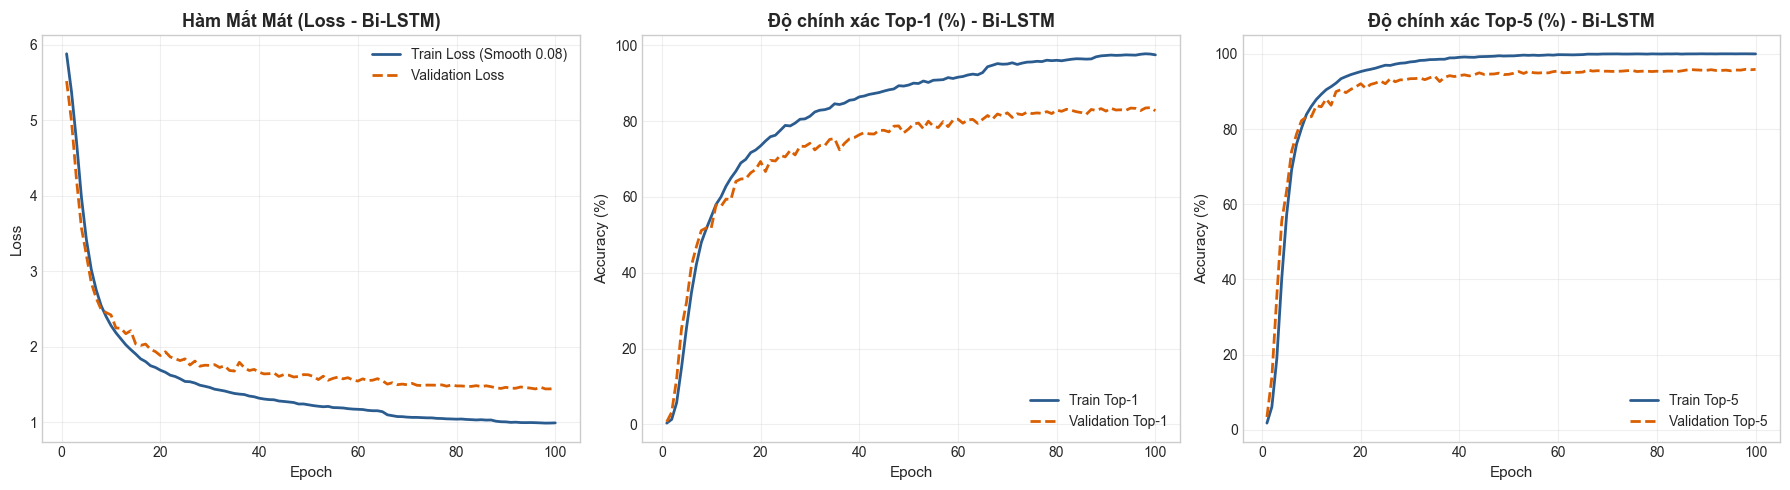

In [26]:
history_df = pd.read_csv(log_csv_path)
epochs_range = range(1, len(history_df) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Biểu đồ Loss
axes[0].plot(epochs_range, history_df['loss'], color='#2b5c8f', linewidth=2, label='Train Loss (Smooth 0.08)')
axes[0].plot(epochs_range, history_df['val_loss'], color='#d95f02', linewidth=2, linestyle='--', label='Validation Loss')
axes[0].set_title('Hàm Mất Mát (Loss - Bi-LSTM)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Loss', fontsize=11)
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

# 2. Biểu đồ Top-1 Accuracy
axes[1].plot(epochs_range, history_df['top_1_acc'] * 100, color='#2b5c8f', linewidth=2, label='Train Top-1')
axes[1].plot(epochs_range, history_df['val_top_1_acc'] * 100, color='#d95f02', linewidth=2, linestyle='--', label='Validation Top-1')
axes[1].set_title('Độ chính xác Top-1 (%) - Bi-LSTM', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Accuracy (%)', fontsize=11)
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)

# 3. Biểu đồ Top-5 Accuracy
axes[2].plot(epochs_range, history_df['top_5_acc'] * 100, color='#2b5c8f', linewidth=2, label='Train Top-5')
axes[2].plot(epochs_range, history_df['val_top_5_acc'] * 100, color='#d95f02', linewidth=2, linestyle='--', label='Validation Top-5')
axes[2].set_title('Độ chính xác Top-5 (%) - Bi-LSTM', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Epoch', fontsize=11)
axes[2].set_ylabel('Accuracy (%)', fontsize=11)
axes[2].legend(loc='lower right')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
fig_path = FIGURES_DIR / "fig_exp1_3_bilstm_learning_curves.png"
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Biểu đồ đường cong học tập đã được lưu tại: {fig_path}")
plt.show()


---
## 9. Đánh Giá Khả Năng Tổng Quát Hóa Trên Người Ký Mới (Unseen Signers Test)


In [27]:
best_model_path = checkpoint_path
print(f"Nạp trọng số tối ưu từ: {best_model_path}")
best_model = keras.models.load_model(best_model_path)

test_results = best_model.evaluate(test_ds, verbose=1)
test_loss = float(test_results[0])
test_top1_acc = float(test_results[1])
test_top5_acc = float(test_results[2])

print(f"\nKẾT QUẢ ĐÁNH GIÁ TRÊN TẬP KIỂM THỬ UNSEEN SIGNERS (P24-P26):")
print(f"- Test Loss          : {test_loss:.4f}")
print(f"- Test Top-1 Accuracy: {test_top1_acc * 100:.2f}%")
print(f"- Test Top-5 Accuracy: {test_top5_acc * 100:.2f}%")

# Lưu chỉ số kiểm định ra tệp JSON
history_df = pd.read_csv(log_csv_path)
best_epoch = int(history_df['val_top_1_acc'].idxmax()) + 1
best_val_row = history_df.iloc[best_epoch - 1]

metrics_record = {
    'experiment': 'bilstm',
    'model_name': model.name,
    'total_params': int(model.count_params()),
    'epochs_trained': len(history_df),
    'best_epoch': best_epoch,
    'best_val_loss': float(best_val_row['val_loss']),
    'best_val_top_1_acc': float(best_val_row['val_top_1_acc']),
    'best_val_top_5_acc': float(best_val_row['val_top_5_acc']),
    'test_loss': test_loss,
    'test_top_1_acc': test_top1_acc,
    'test_top_5_acc': test_top5_acc,
    'elapsed_min': float(globals().get('elapsed_min', 0.0))
}

metrics_json_path = RESULTS_DIR / 'metrics_exp1_3_bilstm.json'
with open(metrics_json_path, 'w', encoding='utf-8') as f:
    json.dump(metrics_record, f, indent=4, ensure_ascii=False)
print(f"Đã lưu trữ chỉ số kiểm định tại: {metrics_json_path}")


Nạp trọng số tối ưu từ: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\checkpoints\vsl400_exp1_bilstm.keras
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 1.5468 - top_1_acc: 0.7941 - top_5_acc: 0.9446

KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP KIỂM THỬ UNSEEN SIGNERS (P24-P26):
- Test Loss          : 1.5468
- Test Top-1 Accuracy: 79.41%
- Test Top-5 Accuracy: 94.46%
Đã lưu trữ chỉ số kiểm định tại: D:\Hoc Tap\VSL Recognition System\VSL-Recognition-System\experiments\results\metrics_exp1_3_bilstm.json


---
## 10. Tổng Kết Tuần 1: Bảng Đối Soát Toàn Diện Các Kiến Trúc Xương Sống (Backbone Comparison)

Tự động tổng hợp và đối soát toàn diện hiệu năng của cả 3 thực nghiệm nền tảng trong Tuần 1:
- **Thực nghiệm 1.1**: Baseline (Standard Conv1D + 1-Layer Bi-GRU)
- **Thực nghiệm 1.2**: Multi-Scale Inception 1D-CNN + 1-Layer Bi-GRU
- **Thực nghiệm 1.3**: Multi-Scale Inception 1D-CNN + 1-Layer Bi-LSTM

Từ đó so sánh trực diện năng lực trích xuất chuỗi thời gian giữa GRU và LSTM trên chuỗi 64 khung hình, chính thức **Khóa Kiến trúc Xương sống (Backbone)** chiến thắng để chuyển giao sang Tuần 2 (Tích hợp Cơ chế Attention).


In [28]:
records = []
metric_files = [
    ('Exp 1.1: Baseline (1D-CNN + Bi-GRU)', RESULTS_DIR / 'metrics_exp1_baseline.json'),
    ('Exp 1.2: Inception + Bi-GRU', RESULTS_DIR / 'metrics_exp1_2_inception.json'),
    ('Exp 1.3: Inception + Bi-LSTM', RESULTS_DIR / 'metrics_exp1_3_bilstm.json')
]

for label, p in metric_files:
    if p.exists():
        with open(p, 'r', encoding='utf-8') as f:
            data = json.load(f)
            records.append({
                'Thực nghiệm': label,
                'Số tham số': f"{data.get('total_params', 0):,}",
                'Epoch tối ưu': f"{data.get('best_epoch', 0)} / {data.get('epochs_trained', 0)}",
                'Validation Top-1 (%)': f"{data.get('best_val_top_1_acc', 0)*100:.2f}%",
                'Validation Top-5 (%)': f"{data.get('best_val_top_5_acc', 0)*100:.2f}%",
                'Test Top-1 (%)': f"{data.get('test_top_1_acc', 0)*100:.2f}%",
                'Test Top-5 (%)': f"{data.get('test_top_5_acc', 0)*100:.2f}%",
                'Test Loss': f"{data.get('test_loss', 0.0):.4f}",
                'Thời gian (phút)': f"{data.get('elapsed_min', 0):.1f}"
            })

if records:
    comp_df = pd.DataFrame(records)
    print('=' * 110)
    print('TỔNG KẾT TUẦN 1: BẢNG SO SÁNH HIỆU NĂNG CÁC KIẾN TRÚC XƯƠNG SỐNG (BACKBONE COMPARISON)')
    print('=' * 110)
    display(comp_df)
    
    best_rec = max(records, key=lambda r: float(r['Test Top-1 (%)'].rstrip('%')))
    print(f"\n=> MÔ HÌNH CHIẾN THẮNG TUẦN 1 (DẪN ĐẦU TEST TOP-1): {best_rec['Thực nghiệm']}")
    print(f"   - Test Top-1 Accuracy: {best_rec['Test Top-1 (%)']}")
    print(f"   - Test Top-5 Accuracy: {best_rec['Test Top-5 (%)']}")
    print("\n=> Sẵn sàng bàn giao kiến trúc chiến thắng sang Tuần 2: Tích hợp Cơ chế Attention (MLP-Attention vs Self-Attention)!")
else:
    print('Chưa có dữ liệu kết quả để so sánh.')


TỔNG KẾT TUẦN 1: BẢNG SO SÁNH HIỆU NĂNG CÁC KIẾN TRÚC XƯƠNG SỐNG (BACKBONE COMPARISON)


,Thực nghiệm,Số tham số,Epoch tối ưu,Validation Top-1 (%),Validation Top-5 (%),Test Top-1 (%),Test Top-5 (%),Test Loss,Thời gian (phút)
0,Exp 1.1: Baseline (1D-CNN + Bi-GRU),"404,688",96 / 100,74.01%,93.27%,70.72%,92.59%,1.7806,40.1
1,Exp 1.2: Inception + Bi-GRU,"762,512",92 / 100,82.84%,95.37%,79.67%,95.65%,1.4930,75.7
2,Exp 1.3: Inception + Bi-LSTM,"860,304",99 / 100,83.52%,95.77%,79.41%,94.46%,1.5468,92.7



=> MÔ HÌNH CHIẾN THẮNG TUẦN 1 (DẪN ĐẦU TEST TOP-1): Exp 1.2: Inception + Bi-GRU
   - Test Top-1 Accuracy: 79.67%
   - Test Top-5 Accuracy: 95.65%

=> Sẵn sàng bàn giao kiến trúc chiến thắng sang Tuần 2: Tích hợp Cơ chế Attention (MLP-Attention vs Self-Attention)!
